# Exercice 32 - Équivalence de deux automates

On construit les deux AEFD de la Figure 6.2 afin de vérifier leur équivalence avec les trois méthodes demandées.

In [2]:
from automata_extensions.fa.dfa import ExtendedDFA



## 1. Construction des automates

Nous commençons par construire les deux automates de la Figure 6.2.

In [3]:
A = ExtendedDFA(
    states={1, 2, 3, 4, 5},
    input_symbols={"0", "1"},
    transitions={
        1: {
            "1": 2,
        },
        2: {
            "0": 5,
            "1": 3,
        },
        3: {},
        4: {
            "0": 5,
        },
        5: {
            "0": 3,
            "1": 4,
        },
    },
    initial_state=1,
    final_states={1, 5},
    allow_partial=True,
)

Composantes fortement connexes :
frozenset({3})
frozenset({4, 5})
frozenset({2})
frozenset({1})


In [32]:
animation = A.animate("1010")
animation

'<!doctype html>\n<html lang="fr">\n<head>\n<meta charset="utf-8">\n<title>Automatix — lecture d\'un mot</title>\n<style>\nbody { margin: 0; padding: 1.5rem; background: #10172b; color: #edf5ff;\n       font: 16px/1.5 system-ui, sans-serif; }\n.automatix-player { max-width: 38rem; margin: auto; padding: 1.4rem;\n                    border: 1px solid #48628d; border-radius: 1rem;\n                    background: #1b2845; }\n.automatix-player h1 { margin: 0 0 .7rem; font-size: 1.3rem; }\n.automatix-player .state { display: inline-grid; place-items: center;\n                           min-width: 5rem; min-height: 5rem; margin: 1rem 0;\n                           padding: .5rem; border: 2px solid #69daf4;\n                           border-radius: 50%; font-weight: 700; }\n.automatix-player .controls { display: flex; gap: .5rem; flex-wrap: wrap; }\n.automatix-player button { padding: .5rem .8rem; border: 0; border-radius: .4rem;\n                           color: #10172b; background: #8de8

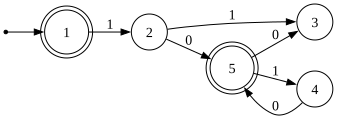

In [4]:
A.show_diagram()

In [5]:
B = ExtendedDFA(
    states={0, 1, 2},
    input_symbols={"0", "1"},
    transitions={
        0: {
            "1": 1,
        },
        1: {
            "0": 0,
            "1": 2,
        },
        2: {},
    },
    initial_state=0,
    final_states={0},
    allow_partial=True,
)

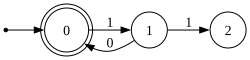

In [6]:
B.show_diagram()

## 1. Équivalence par distinguabilité

On place les deux automates complétés dans un même DFA, en renommant leurs états.  
On teste ensuite si leurs deux états initiaux sont distinguables.

In [8]:
C = ExtendedDFA(
    states={
        "A1", "A2", "A3", "A4", "A5", "PA",
        "B0", "B1", "B2", "PB",
    },
    input_symbols={"0", "1"},
    transitions={
        # Automate A
        "A1": {"0": "PA", "1": "A2"},
        "A2": {"0": "A5", "1": "A3"},
        "A3": {"0": "PA", "1": "PA"},
        "A4": {"0": "A5", "1": "PA"},
        "A5": {"0": "A3", "1": "A4"},
        "PA": {"0": "PA", "1": "PA"},

        # Automate B
        "B0": {"0": "PB", "1": "B1"},
        "B1": {"0": "B0", "1": "B2"},
        "B2": {"0": "PB", "1": "PB"},
        "PB": {"0": "PB", "1": "PB"},
    },
    initial_state="A1",
    final_states={"A1", "A5", "B0"},
)

In [19]:
print(C.pair_table_str(show_round=True))

  A1 A2 A3 A4 A5 B0 B1 B2 PA
A2  0
A3  0  1
A4  0  .  1
A5  .  0  0  0
B0  .  0  0  0  .
B1  0  .  1  .  0  0
B2  0  1  .  1  0  0  1
PA  0  1  .  1  0  0  1  .
PB  0  1  .  1  0  0  1  .  .


In [27]:
from automata_extensions.utils.patches import patch_cached_method

print("Patch déjà actif :", not patch_cached_method())

Patch déjà actif : True


In [10]:
distinguables = C.distinguishable_states()

initiaux = frozenset({"A1", "B0"})

print("États initiaux :", initiaux)
print("Sont-ils distinguables ?", initiaux in distinguables)

États initiaux : frozenset({'A1', 'B0'})
Sont-ils distinguables ? False


In [11]:
classes = C.equivalence_classes()

for classe in classes:
    print(sorted(classe))

['A1', 'A5', 'B0']
['A2', 'A4', 'B1']
['A3', 'B2', 'PA', 'PB']


Les états initiaux `A1` et `B0` ne sont pas distinguables. Ils reconnaissent donc le même langage : les deux automates sont équivalents.

## 2. Équivalence par minimisation

On minimise les deux automates puis on compare les automates minimaux obtenus.

In [12]:
A_min = A.complete().minimize()
B_min = B.complete().minimize()

print("Nombre d'états de A minimisé :", len(A_min.states))
print("Nombre d'états de B minimisé :", len(B_min.states))
print("Automates minimaux isomorphes :", A_min.is_isomorphic_to(B_min))

Nombre d'états de A minimisé : 3
Nombre d'états de B minimisé : 3
Automates minimaux isomorphes : True


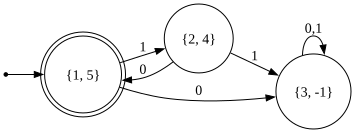

In [13]:
A_min.show_diagram()

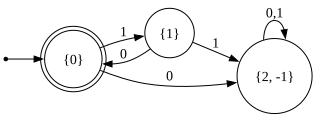

In [14]:
B_min.show_diagram()

In [15]:
print(
    "Les automates minimaux sont isomorphes :",
    A_min.is_isomorphic_to(B_min)
)

Les automates minimaux sont isomorphes : True


Les deux automates se minimisent en des DFA à 3 états qui sont isomorphes. Ils reconnaissent donc le même langage.

## 3. Équivalence par produit d'automates

On construit le produit des deux automates. Un état du produit est final si un seul des deux automates accepte.

In [16]:
A_complet = A.complete()
B_complet = B.complete()

P = A_complet.product(
    B_complet,
    is_final=lambda qA, qB:
        (qA in A_complet.final_states) != (qB in B_complet.final_states)
)

print("États finaux du produit :", P.final_states)
print("Langage du produit vide :", P.is_empty())

États finaux du produit : frozenset()
Langage du produit vide : True


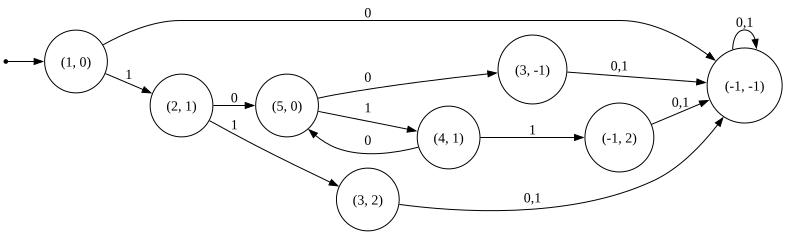

In [17]:
P.show_diagram()

Le langage du produit différentiel est vide : aucun mot ne distingue les deux automates. Ils sont donc équivalents.

## Conclusion

Les trois méthodes montrent que les deux automates reconnaissent le même langage. Ils sont donc équivalents.